# CIFAR-10 Image Classifier: Improved

The [original notebook](CIFAR-10_Image_Classifier-STARTER.ipynb) reached **75.98%** test accuracy with a
3-layer CNN. This notebook keeps the same dataset and augmentation and changes four things:

| Change | v1 (original) | v2 (this notebook) |
|---|---|---|
| Hardware | CPU (model and data were never moved to GPU) | GPU |
| Normalization | none | `BatchNorm2d` after every conv layer |
| Network | 3 conv layers, 16 → 64 filters | 6 conv layers in VGG-style blocks, 64 → 256 filters, global average pooling |
| Training | Adam, fixed lr 0.001, 20 epochs | SGD + Nesterov momentum, OneCycle lr schedule, weight decay, 30 epochs |

In [1]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu")

Device: NVIDIA GeForce GTX 1650


## Load the Dataset

Same augmentation as v1 (random crop + horizontal flip). Normalization now uses the real per-channel
CIFAR-10 mean and standard deviation instead of 0.5.

In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

batch_size = 128
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True,
                                          num_workers=4, pin_memory=True, persistent_workers=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False,
                                         num_workers=4, pin_memory=True)
classes = trainset.classes
print(f"{len(trainset)} train / {len(testset)} test images, classes: {classes}")

50000 train / 10000 test images, classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Build the Network

Three VGG-style blocks of two `conv → BatchNorm → ReLU` layers each, followed by max pooling and
dropout. Global average pooling replaces the large fully connected layers of v1.

In [3]:
def conv_bn(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )


class Model(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn(3, 64), conv_bn(64, 64), nn.MaxPool2d(2), nn.Dropout(0.1),      # 32 -> 16
            conv_bn(64, 128), conv_bn(128, 128), nn.MaxPool2d(2), nn.Dropout(0.2),  # 16 -> 8
            conv_bn(128, 256), conv_bn(256, 256), nn.MaxPool2d(2), nn.Dropout(0.3), # 8 -> 4
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.classifier(x)


model = Model().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,148,874


Loss, optimizer and learning-rate schedule. OneCycle warms the learning rate up and then anneals it,
which trains faster and more stably than a fixed rate.

In [4]:
num_epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=num_epochs,
                                          steps_per_epoch=len(trainloader))

## Train

Training runs in full fp32. Mixed precision (fp16) was tried first and dropped: on this GTX 1650 it was
about 6× slower per epoch (92 s vs 15 s) and produced NaN outputs at evaluation time.

Test accuracy is logged each epoch only to plot the learning curve; nothing is tuned or selected on it,
and the final model is the last epoch's.

In [5]:
def evaluate(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for data, targets in loader:
            data, targets = data.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            correct += (model(data).argmax(1) == targets).sum().item()
            total += targets.size(0)
    return 100 * correct / total


history = {"loss": [], "train_acc": [], "test_acc": []}
start = time.time()

for epoch in range(num_epochs):
    model.train()
    total_loss = correct = total = 0
    for data, targets in trainloader:
        data, targets = data.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        scores = model(data)
        loss = criterion(scores, targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * targets.size(0)
        correct += (scores.argmax(1) == targets).sum().item()
        total += targets.size(0)

    history["loss"].append(total_loss / total)
    history["train_acc"].append(100 * correct / total)
    history["test_acc"].append(evaluate(testloader))
    print(f"Epoch {epoch + 1:2d}/{num_epochs} | loss {history['loss'][-1]:.4f} | "
          f"train acc {history['train_acc'][-1]:.2f}% | test acc {history['test_acc'][-1]:.2f}% | "
          f"{time.time() - start:.0f}s")

print(f"\nTraining finished in {(time.time() - start) / 60:.1f} min")

Epoch  1/30 | loss 1.3796 | train acc 49.52% | test acc 58.62% | 18s


Epoch  2/30 | loss 0.9804 | train acc 65.04% | test acc 64.35% | 35s


Epoch  3/30 | loss 0.8205 | train acc 71.32% | test acc 67.31% | 52s


Epoch  4/30 | loss 0.7239 | train acc 74.74% | test acc 65.48% | 69s


Epoch  5/30 | loss 0.6524 | train acc 77.40% | test acc 73.01% | 86s


Epoch  6/30 | loss 0.5988 | train acc 79.36% | test acc 74.87% | 103s


... (20 outputs left out)

Epoch 27/30 | loss 0.1893 | train acc 93.61% | test acc 90.62% | 463s


Epoch 28/30 | loss 0.1626 | train acc 94.49% | test acc 91.51% | 480s


Epoch 29/30 | loss 0.1411 | train acc 95.36% | test acc 91.67% | 497s


Epoch 30/30 | loss 0.1315 | train acc 95.69% | test acc 91.64% | 515s

Training finished in 8.6 min


## Learning Curves

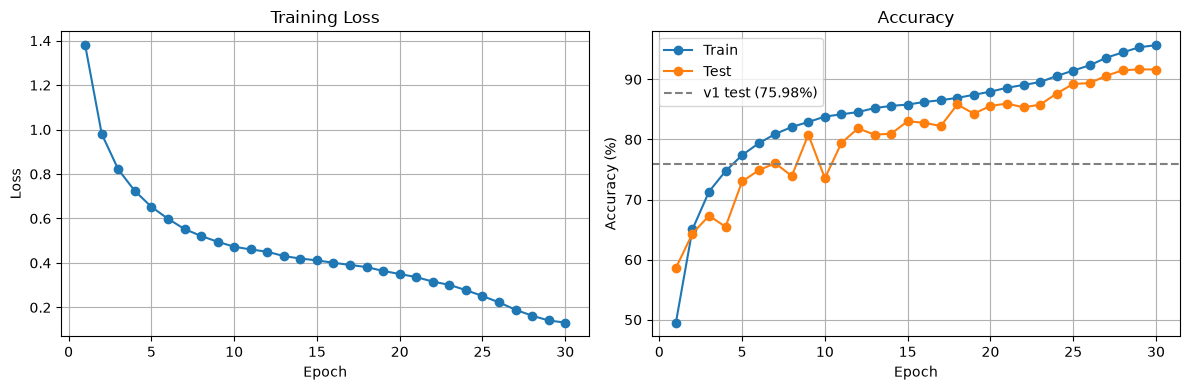

In [6]:
epochs = range(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, history["loss"], marker="o")
ax1.set(title="Training Loss", xlabel="Epoch", ylabel="Loss")
ax1.grid()
ax2.plot(epochs, history["train_acc"], marker="o", label="Train")
ax2.plot(epochs, history["test_acc"], marker="o", label="Test")
ax2.axhline(75.98, color="gray", linestyle="--", label="v1 test (75.98%)")
ax2.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
ax2.grid()
ax2.legend()
plt.tight_layout()
plt.show()

## Test the Model

In [7]:
accuracy = evaluate(testloader)
print(f"The test accuracy is {accuracy:.2f}% (v1: 75.98%)")

# Per-class accuracy
model.eval()
class_correct, class_total = np.zeros(10), np.zeros(10)
with torch.no_grad():
    for data, targets in testloader:
        preds = model(data.to(device)).argmax(1).cpu()
        for t, p in zip(targets, preds):
            class_total[t] += 1
            class_correct[t] += int(t == p)
for name, c, t in zip(classes, class_correct, class_total):
    print(f"{name:>10}: {100 * c / t:.1f}%")

The test accuracy is 91.64% (v1: 75.98%)


  airplane: 91.8%
automobile: 96.1%
      bird: 86.8%
       cat: 81.2%
      deer: 93.1%
       dog: 87.7%
      frog: 95.2%
     horse: 94.2%
      ship: 96.0%
     truck: 94.3%


## Save the Model

In [8]:
torch.save(model.state_dict(), "cifar10_cnn_v2.pth")

## Summary

| | v1 (original) | v2 (this notebook) |
|---|---|---|
| Test accuracy | 75.98% | **91.64%** |
| Train accuracy (last epoch) | 74.05% | 95.69% |
| Parameters | 0.16M | 1.15M |
| Training time | CPU | 8.6 min on a GTX 1650 |

* Test accuracy improved by **15.7 points**. v1 was underfitting (train accuracy below test accuracy); the deeper
  network with batch normalization has the capacity to fit the data, and the OneCycle schedule's final
  low-learning-rate epochs account for the last jump from ~86% to ~92%.
* The hardest classes are **cat (81.2%)**, bird (86.8%) and dog (87.7%), the visually similar animal
  classes; vehicles and ships are all above 94%.
* Mixed precision (fp16) was not usable on this GPU: it was about 6× slower per epoch and returned NaN
  outputs at evaluation time, so the model trains in fp32.